# 04 — Baseline Task 2: Performance Error Detection

Dorfer-lite adapted baseline: score crop + audio error -> 4 kelas.

## 0. Data

`task2_windows_*` + `score_crops_*`; referensi = crop notehead sumber.

## 1. Setup

In [1]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed").exists():
    raise RuntimeError(
        "Jalankan notebook dari root repo atau dari folder notebooks/. "
        f"Path saat ini: {ROOT}"
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.baseline_dorfer import (
    CLASS_NAMES,
    AudioEncoder,
    SheetEncoder,
    Task2Dataset,
    Task2Model,
    binary_metrics,
    classification_metrics,
    configure_torch,
    count_parameters,
    embed_image_rows,
    load_checkpoint,
    resolve_device,
    save_json,
    set_seed,
    topk_accuracy,
)

DATA_DIR = ROOT / "data" / "processed"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
CKPT_DIR = ROOT / "checkpoints"
for directory in (REPORTS_DIR, FIG_DIR, CKPT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

TASK1_CHECKPOINT = CKPT_DIR / "baseline_task1_dual_encoder.pt"
CHECKPOINT_PATH = CKPT_DIR / "baseline_task2_multimodal_classifier.pt"

CONFIG = {
    "profile": "dorfer-lite",
    "seed": 42,
    "device": "auto",
    "threads": None,
    "embed_dim": 32,
    "channels": (16, 32, 64),
    "hidden_dim": 128,
    "dropout": 0.2,
    "num_classes": 4,
    "batch_size": 256,
    "eval_batch_size": 512,
    "epochs": 8,
    "early_stop_patience": 3,
    "lr_encoder": 5e-4,
    "lr_head": 1e-3,
    "weight_decay": 1e-5,
    "grad_clip": 5.0,
    "freeze_sheet": True,
    "train_one_variant_per_source": True,
    "num_workers": 0,
    "fast_dev": False,
}

SEED = int(CONFIG["seed"])
set_seed(SEED)
configure_torch(CONFIG["threads"])
DEVICE = resolve_device(CONFIG["device"])

print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)
print("Task 1 checkpoint:", TASK1_CHECKPOINT)

PyTorch : 2.15.0+cpu
Device  : cpu
Task 1 checkpoint: <project-root>\checkpoints\baseline_task1_dual_encoder.pt


## 2. Verifikasi artefak

In [2]:
if not TASK1_CHECKPOINT.exists():
    raise FileNotFoundError(
        "Checkpoint Task 1 belum ada. Jalankan notebook 03 terlebih dahulu: "
        f"{TASK1_CHECKPOINT}"
    )

SPLITS = ["train", "val", "test"]
required = []
for split in SPLITS:
    required.extend([
        DATA_DIR / f"error_windows_{split}.npy",
        DATA_DIR / f"task2_windows_{split}.parquet",
        DATA_DIR / f"score_crops_{split}.npy",
        DATA_DIR / f"noteheads_{split}.parquet",
    ])

missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Artefak Task 2 belum lengkap. Ekstrak preproc-v1-task2.zip dan "
        "preproc-v1-core.zip ke root repo:\n" + "\n".join(missing)
    )

print("Semua artefak Task 2 ditemukan.")
for split in SPLITS:
    errors = np.load(DATA_DIR / f"error_windows_{split}.npy", mmap_mode="r")
    meta = pd.read_parquet(DATA_DIR / f"task2_windows_{split}.parquet")
    assert errors.shape[1:] == (42, 92), errors.shape
    assert len(meta) == errors.shape[0]
    assert np.array_equal(
        np.sort(meta["error_row"].to_numpy()), np.arange(len(meta))
    )
    print(f"{split:5s} error_windows={errors.shape} meta={len(meta):,}")

Semua artefak Task 2 ditemukan.
train error_windows=(114920, 42, 92) meta=114,920
val   error_windows=(38880, 42, 92) meta=38,880


test  error_windows=(32288, 42, 92) meta=32,288


## 3. Audit data

In [3]:
meta_frames = {
    split: pd.read_parquet(DATA_DIR / f"task2_windows_{split}.parquet").reset_index(drop=True)
    for split in SPLITS
}

rows = []
for split in SPLITS:
    meta = meta_frames[split]
    rows.append({
        "split": split,
        "rows": len(meta),
        "source_windows": meta["source_window_id"].nunique(),
        "classes": meta["class_name"].value_counts().to_dict(),
        "soundfonts": meta["soundfont"].nunique(),
        "pieces": meta["piece"].nunique(),
        "work_groups": meta["work_group"].nunique(),
    })
display(pd.DataFrame(rows))

for split in SPLITS:
    meta = meta_frames[split]
    variants = meta.groupby("source_window_id").size()
    assert variants.eq(4).all(), f"{split}: ada source window tanpa 4 varian"
    print(f"{split:5s}: setiap source window punya 4 varian (clean/wrong/delete/insert).")

,split,rows,source_windows,classes,soundfonts,pieces,work_groups
0,train,114920,28730,"{'clean': 28730, 'wrong_pitch': 28730, 'delete...",4,17,17
1,val,38880,9720,"{'clean': 9720, 'wrong_pitch': 9720, 'delete':...",4,4,4
2,test,32288,8072,"{'clean': 8072, 'wrong_pitch': 8072, 'delete':...",4,3,3


train: setiap source window punya 4 varian (clean/wrong/delete/insert).
val  : setiap source window punya 4 varian (clean/wrong/delete/insert).
test : setiap source window punya 4 varian (clean/wrong/delete/insert).


In [4]:
work_groups = {
    split: set(meta_frames[split]["work_group"]) for split in SPLITS
}
assert work_groups["train"].isdisjoint(work_groups["val"])
assert work_groups["train"].isdisjoint(work_groups["test"])
assert work_groups["val"].isdisjoint(work_groups["test"])
print("Split work_group bersih: tidak ada irisan.")

for split in SPLITS:
    noteheads = pd.read_parquet(DATA_DIR / f"noteheads_{split}.parquet")
    missing = set(meta_frames[split]["notehead_id"]) - set(noteheads["notehead_id"])
    assert not missing, f"{split}: {len(missing)} notehead tanpa score crop"
    print(f"{split:5s}: semua notehead_id punya score crop di core.")

for split in SPLITS:
    meta = meta_frames[split]
    print(f"\n[{split}] soundfont")
    print(meta["soundfont"].value_counts().to_string())
    print(f"[{split}] class")
    print(meta["class_name"].value_counts().to_string())

Split work_group bersih: tidak ada irisan.
train: semua notehead_id punya score crop di core.
val  : semua notehead_id punya score crop di core.
test : semua notehead_id punya score crop di core.

[train] soundfont
soundfont
ElectricPiano               57460
YamahaGrandPiano            28496
grand-piano-YDP-20160804    16460
acoustic_piano_imis_1       12504
[train] class
class_name
clean          28730
wrong_pitch    28730
delete         28730
insert         28730

[val] soundfont
soundfont
acoustic_piano_imis_1       11924
ElectricPiano                9720
grand-piano-YDP-20160804     9720
YamahaGrandPiano             7516
[val] class
class_name
clean          9720
wrong_pitch    9720
delete         9720
insert         9720

[test] soundfont
soundfont
acoustic_piano_imis_1       8072
ElectricPiano               8072
grand-piano-YDP-20160804    8072
YamahaGrandPiano            8072
[test] class
class_name
clean          8072
wrong_pitch    8072
delete         8072
insert         8072


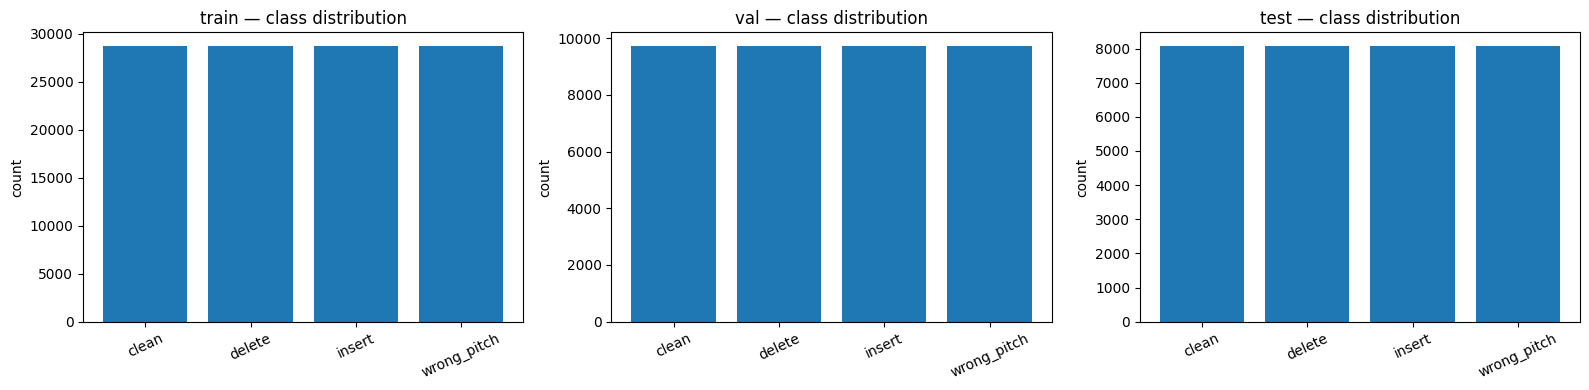

wrong_pitch |pitch_delta| describe:
count    28730.000000
mean         6.446606
std          3.459459
min          1.000000
25%          3.000000
50%          6.000000
75%          9.000000
max         12.000000


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, split in zip(axes, SPLITS):
    counts = meta_frames[split]["class_name"].value_counts().sort_index()
    axis.bar(counts.index, counts.values)
    axis.set_title(f"{split} — class distribution")
    axis.set_ylabel("count")
    axis.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIG_DIR / "25_baseline_task2_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

wrong = meta_frames["train"].loc[meta_frames["train"]["class_id"] == 1, "pitch_delta"].abs()
print("wrong_pitch |pitch_delta| describe:")
print(wrong.describe().to_string())

## 4. Model

Encoder Task 1; sheet frozen; fusion `[x, y, x*y, abs(x-y)]` -> MLP -> 4 kelas.

In [6]:
task1_checkpoint = load_checkpoint(TASK1_CHECKPOINT, map_location="cpu")
for key in ("sheet_encoder", "audio_encoder"):
    if key not in task1_checkpoint:
        raise KeyError(f"Checkpoint Task 1 tidak punya '{key}'.")

task1_channels = tuple(
    task1_checkpoint.get("config", {}).get("channels", (24, 48, 96, 96))
)
if task1_channels != tuple(CONFIG["channels"]):
    raise ValueError(
        "Konfigurasi channels Task 2 tidak cocok dengan checkpoint Task 1: "
        f"{tuple(CONFIG['channels'])} vs {task1_channels}. "
        "Jalankan ulang notebook 03 dengan profil yang sama."
    )

sheet_encoder = SheetEncoder(
    embed_dim=CONFIG["embed_dim"], channels=CONFIG["channels"]
)
audio_encoder = AudioEncoder(
    embed_dim=CONFIG["embed_dim"], channels=CONFIG["channels"]
)
sheet_encoder.load_state_dict(task1_checkpoint["sheet_encoder"])
audio_encoder.load_state_dict(task1_checkpoint["audio_encoder"])

model = Task2Model(
    sheet_encoder=sheet_encoder,
    audio_encoder=audio_encoder,
    embed_dim=CONFIG["embed_dim"],
    hidden_dim=CONFIG["hidden_dim"],
    num_classes=CONFIG["num_classes"],
    dropout=CONFIG["dropout"],
).to(DEVICE)

if CONFIG["freeze_sheet"]:
    for parameter in model.sheet.parameters():
        parameter.requires_grad = False

print(f"Total parameters    : {count_parameters(model):,}")
print(f"Trainable parameters: {count_parameters(model, trainable_only=True):,}")
print("Sheet frozen        :", CONFIG["freeze_sheet"])
print("Task 1 val metrics  :", task1_checkpoint.get("val_metrics"))
print(model)

Total parameters    : 165,284
Trainable parameters: 91,156
Sheet frozen        : True
Task 1 val metrics  : {'mrr_a2s': 0.009223142917489378, 'mrr_s2a': 0.008063890564363718, 'mrr_mean': 0.008643516740926548, 'n': 2430}
Task2Model(
  (sheet): SheetEncoder(
    (blocks): Sequential(
      (0): ConvStack(
        (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): ELU(alpha=1.0, inplace=True)
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): ConvStack(
        (conv1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(32, eps

## 5. Dataset

Satu varian acak per source per epoch; validation/test semua varian.

In [7]:
def subsample_meta(meta, per_class, seed):
    parts = [
        group.sample(n=min(per_class, len(group)), random_state=seed)
        for _, group in meta.groupby("class_id")
    ]
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

def build_task2_split(split):
    meta = meta_frames[split].copy()
    if CONFIG["fast_dev"]:
        per_class = 1000 if split == "train" else (250 if split == "val" else None)
        if per_class is not None:
            meta = subsample_meta(meta, per_class, SEED)
    noteheads = pd.read_parquet(DATA_DIR / f"noteheads_{split}.parquet")
    unique_noteheads = (
        noteheads[noteheads["notehead_id"].isin(meta["notehead_id"].unique())]
        .sort_values("crop_row")
        .reset_index(drop=True)
    )
    notehead_to_bank = {
        notehead_id: index
        for index, notehead_id in enumerate(unique_noteheads["notehead_id"])
    }
    bank_indices = meta["notehead_id"].map(notehead_to_bank).to_numpy()
    assert not pd.isna(bank_indices).any()
    bank_indices = bank_indices.astype(int)

    bank = None
    if CONFIG["freeze_sheet"]:
        bank_path = CKPT_DIR / f"task2_score_bank_{split}.pt"
        task1_mtime = TASK1_CHECKPOINT.stat().st_mtime
        if bank_path.exists():
            cached = load_checkpoint(bank_path, map_location="cpu")
            expected_ids = unique_noteheads["notehead_id"].tolist()
            if (
                cached.get("notehead_ids") == expected_ids
                and cached.get("task1_mtime") == task1_mtime
            ):
                bank = cached["bank"]
                print(f"[{split}] score bank dimuat dari cache: {bank.shape}")
        if bank is None:
            bank = embed_image_rows(
                model.sheet,
                DATA_DIR / f"score_crops_{split}.npy",
                unique_noteheads["crop_row"].to_numpy(),
                batch_size=CONFIG["eval_batch_size"],
                device=DEVICE,
                normalize=True,
            )
            torch.save(
                {
                    "bank": bank,
                    "notehead_ids": unique_noteheads["notehead_id"].tolist(),
                    "crop_rows": unique_noteheads["crop_row"].to_numpy(),
                    "task1_mtime": task1_mtime,
                },
                bank_path,
            )
            print(f"[{split}] score bank dihitung: {bank.shape} -> {bank_path}")

    return meta, noteheads, unique_noteheads, bank_indices, bank

train_meta, train_noteheads, train_unique, train_bank_idx, train_bank = build_task2_split("train")
val_meta, val_noteheads, val_unique, val_bank_idx, val_bank = build_task2_split("val")
test_meta, test_noteheads, test_unique, test_bank_idx, test_bank = build_task2_split("test")

[train] score bank dihitung: torch.Size([14365, 32]) -> <project-root>\checkpoints\task2_score_bank_train.pt


[val] score bank dihitung: torch.Size([2430, 32]) -> <project-root>\checkpoints\task2_score_bank_val.pt


[test] score bank dihitung: torch.Size([2018, 32]) -> <project-root>\checkpoints\task2_score_bank_test.pt


In [8]:
train_dataset = Task2Dataset(
    DATA_DIR / "score_crops_train.npy",
    DATA_DIR / "error_windows_train.npy",
    train_meta,
    train_noteheads,
    score_bank_indices=train_bank_idx if CONFIG["freeze_sheet"] else None,
    one_variant_per_source=CONFIG["train_one_variant_per_source"],
)
val_dataset = Task2Dataset(
    DATA_DIR / "score_crops_val.npy",
    DATA_DIR / "error_windows_val.npy",
    val_meta,
    val_noteheads,
    score_bank_indices=val_bank_idx if CONFIG["freeze_sheet"] else None,
    one_variant_per_source=False,
)
test_dataset = Task2Dataset(
    DATA_DIR / "score_crops_test.npy",
    DATA_DIR / "error_windows_test.npy",
    test_meta,
    test_noteheads,
    score_bank_indices=test_bank_idx if CONFIG["freeze_sheet"] else None,
    one_variant_per_source=False,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
)
val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["eval_batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
)
test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["eval_batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
)

batch = next(iter(train_loader))
if CONFIG["freeze_sheet"]:
    score_index, specs, labels = batch
    print("score bank index:", tuple(score_index.shape), score_index.dtype)
else:
    score_images, specs, labels = batch
    print("score images:", tuple(score_images.shape), score_images.dtype)
print("audio:", tuple(specs.shape), specs.dtype)
print("labels:", tuple(labels.shape), labels.dtype, "| values:", labels.unique().tolist())
print(f"train batches: {len(train_loader):,} | val: {len(val_dataset):,} | test: {len(test_dataset):,}")

score bank index: (256,) torch.int64
audio: (256, 1, 92, 42) torch.float32
labels: (256,) torch.int64 | values: [0, 1, 2, 3]
train batches: 113 | val: 38,880 | test: 32,288


## 6. Training

Cross-entropy; encoder 5e-4; head 1e-3; 8 epoch; early stop 3.

In [9]:
criterion = torch.nn.CrossEntropyLoss()
parameter_groups = [
    {"params": model.classifier.parameters(), "lr": CONFIG["lr_head"]},
    {"params": model.audio.parameters(), "lr": CONFIG["lr_encoder"]},
]
if not CONFIG["freeze_sheet"]:
    parameter_groups.append(
        {"params": model.sheet.parameters(), "lr": CONFIG["lr_encoder"]}
    )
optimizer = torch.optim.Adam(
    parameter_groups,
    weight_decay=CONFIG["weight_decay"],
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

train_bank_device = train_bank.to(DEVICE) if train_bank is not None else None
val_bank_device = val_bank.to(DEVICE) if val_bank is not None else None
test_bank_device = test_bank.to(DEVICE) if test_bank is not None else None

def train_one_epoch_task2(model, loader, optimizer, criterion, device,
                          score_bank, freeze_sheet):
    model.train()
    if freeze_sheet:
        model.sheet.eval()
    total_loss = 0.0
    total_items = 0
    for batch in loader:
        if score_bank is not None:
            score_index, specs, labels = batch
            score_emb = score_bank[score_index.to(device)]
            specs = specs.to(device)
            labels = labels.to(device)
            audio_emb = model.audio(specs)
            logits = model.forward_from_embeddings(score_emb, audio_emb)
        else:
            score_images, specs, labels = batch
            logits = model(score_images.to(device), specs.to(device))
            labels = labels.to(device)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise RuntimeError("Loss Task 2 tidak finite; cek learning rate / data.")
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad],
            CONFIG["grad_clip"],
        )
        optimizer.step()
        total_loss += float(loss.detach()) * labels.size(0)
        total_items += labels.size(0)
    return total_loss / max(total_items, 1)

@torch.no_grad()
def predict_task2(model, loader, device, score_bank, freeze_sheet):
    model.eval()
    probabilities, labels = [], []
    for batch in loader:
        if score_bank is not None:
            score_index, specs, batch_labels = batch
            score_emb = score_bank[score_index.to(device)]
            audio_emb = model.audio(specs.to(device))
            logits = model.forward_from_embeddings(score_emb, audio_emb)
        else:
            score_images, specs, batch_labels = batch
            logits = model(score_images.to(device), specs.to(device))
        probabilities.append(torch.softmax(logits, dim=1).cpu())
        labels.append(batch_labels.cpu())
    return torch.cat(probabilities).numpy(), torch.cat(labels).numpy()

In [10]:
def fit_task2(model, train_loader, val_loader, optimizer, scheduler, criterion,
              config, device, train_bank, val_bank, checkpoint_path):
    history = []
    best_f1 = -1.0
    bad_epochs = 0
    for epoch in range(1, int(config["epochs"]) + 1):
        started = time.time()
        train_loss = train_one_epoch_task2(
            model, train_loader, optimizer, criterion, device,
            train_bank, config["freeze_sheet"],
        )
        probabilities, labels = predict_task2(
            model, val_loader, device, val_bank, config["freeze_sheet"]
        )
        if not np.isfinite(probabilities).all():
            print("Probabilitas validasi tidak finite; training dihentikan.")
            break
        predictions = probabilities.argmax(axis=1)
        metrics = classification_metrics(
            labels, predictions, class_names=CLASS_NAMES,
            num_classes=config["num_classes"],
        )
        metrics["top2_accuracy"] = topk_accuracy(probabilities, labels, k=2)
        if not np.isfinite(metrics["macro_f1"]):
            print("Val macro-F1 tidak finite; training dihentikan.")
            break
        scheduler.step(metrics["macro_f1"])
        elapsed = time.time() - started
        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            **metrics,
            "lr_head": float(optimizer.param_groups[0]["lr"]),
            "seconds": elapsed,
        }
        history.append(record)
        print(
            f"epoch {epoch:02d} | loss {train_loss:.4f} | "
            f"val acc {metrics['accuracy']:.4f} | "
            f"val macro-F1 {metrics['macro_f1']:.4f} | "
            f"top2 {metrics['top2_accuracy']:.4f} | {elapsed:.1f}s"
        )
        if metrics["macro_f1"] > best_f1:
            best_f1 = metrics["macro_f1"]
            bad_epochs = 0
            torch.save(
                {
                    "model_state": model.state_dict(),
                    "config": config,
                    "task1_checkpoint": str(TASK1_CHECKPOINT),
                    "epoch": epoch,
                    "val_metrics": metrics,
                },
                checkpoint_path,
            )
            print(f"  -> checkpoint disimpan (best val macro-F1 {best_f1:.4f})")
        else:
            bad_epochs += 1
            if bad_epochs >= int(config["early_stop_patience"]):
                print(f"Early stop setelah {bad_epochs} epoch tanpa perbaikan.")
                break
    return history, best_f1

## 7. Jalankan training

In [11]:
FAST_DEV_RUN = bool(CONFIG["fast_dev"])
run_epochs = 2 if FAST_DEV_RUN else int(CONFIG["epochs"])
run_patience = 2 if FAST_DEV_RUN else int(CONFIG["early_stop_patience"])
if FAST_DEV_RUN:
    print("FAST_DEV_RUN aktif: subset per kelas, 2 epoch.")

fit_config = dict(CONFIG)
fit_config["epochs"] = run_epochs
fit_config["early_stop_patience"] = run_patience

history, best_f1 = fit_task2(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    fit_config,
    DEVICE,
    train_bank_device,
    val_bank_device,
    CHECKPOINT_PATH,
)
print(f"Best validation macro-F1: {best_f1:.4f}")
print("Checkpoint:", CHECKPOINT_PATH)

epoch 01 | loss 0.6824 | val acc 0.7248 | val macro-F1 0.6786 | top2 0.9490 | 85.0s
  -> checkpoint disimpan (best val macro-F1 0.6786)


epoch 02 | loss 0.2186 | val acc 0.8978 | val macro-F1 0.8967 | top2 0.9803 | 68.7s
  -> checkpoint disimpan (best val macro-F1 0.8967)


epoch 03 | loss 0.1006 | val acc 0.9294 | val macro-F1 0.9290 | top2 0.9879 | 68.3s
  -> checkpoint disimpan (best val macro-F1 0.9290)


epoch 04 | loss 0.0565 | val acc 0.9344 | val macro-F1 0.9337 | top2 0.9934 | 69.4s
  -> checkpoint disimpan (best val macro-F1 0.9337)


epoch 05 | loss 0.0387 | val acc 0.9555 | val macro-F1 0.9555 | top2 0.9990 | 68.4s
  -> checkpoint disimpan (best val macro-F1 0.9555)


epoch 06 | loss 0.0294 | val acc 0.9626 | val macro-F1 0.9626 | top2 0.9995 | 69.7s
  -> checkpoint disimpan (best val macro-F1 0.9626)


epoch 07 | loss 0.0283 | val acc 0.9505 | val macro-F1 0.9502 | top2 0.9919 | 67.8s


epoch 08 | loss 0.0175 | val acc 0.9644 | val macro-F1 0.9643 | top2 0.9989 | 68.6s
  -> checkpoint disimpan (best val macro-F1 0.9643)
Best validation macro-F1: 0.9643
Checkpoint: <project-root>\checkpoints\baseline_task2_multimodal_classifier.pt


,epoch,train_loss,accuracy,macro_f1,n,top2_accuracy,lr_head,seconds
0,1,0.682447,0.724820,0.678573,38880,0.948997,0.001,84.990604
1,2,0.218600,0.897788,0.896651,38880,0.980298,0.001,68.690508
2,3,0.100618,0.929450,0.929031,38880,0.987860,0.001,68.284140
3,4,0.056479,0.934439,0.933742,38880,0.993364,0.001,69.376905
4,5,0.038742,0.955478,0.955460,38880,0.998971,0.001,68.397843
5,6,0.029364,0.962603,0.962608,38880,0.999537,0.001,69.723158
6,7,0.028256,0.950463,0.950181,38880,0.991924,0.001,67.757737
7,8,0.017503,0.964403,0.964310,38880,0.998920,0.001,68.613276


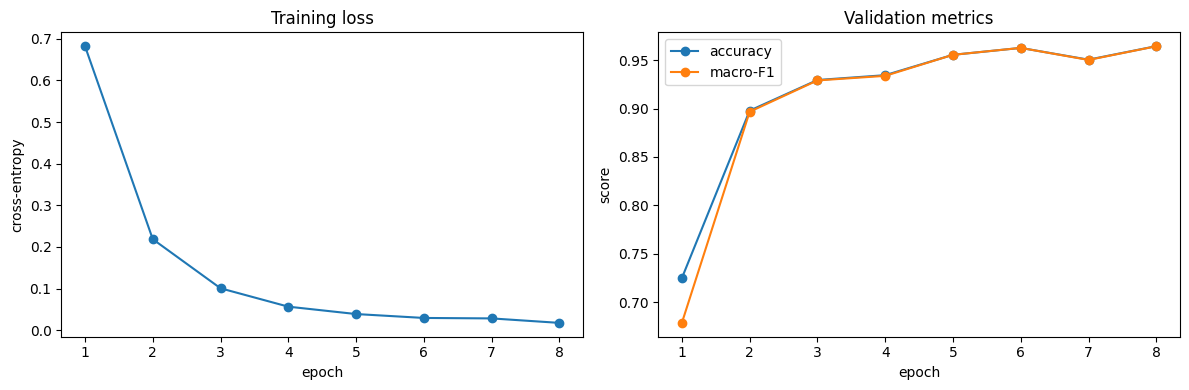

In [12]:
history_df = pd.DataFrame(history)
display(history_df.drop(columns=["confusion_matrix", "per_class"]))
history_df.to_csv(REPORTS_DIR / "baseline_task2_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy")
axes[0].set_title("Training loss")
axes[1].plot(history_df["epoch"], history_df["accuracy"], marker="o", label="accuracy")
axes[1].plot(history_df["epoch"], history_df["macro_f1"], marker="o", label="macro-F1")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("score")
axes[1].set_title("Validation metrics")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "26_baseline_task2_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Evaluasi test

Accuracy, macro-F1, confusion matrix, top-2, binary, error-type.

In [13]:
checkpoint = load_checkpoint(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print("Loaded epoch", checkpoint.get("epoch"))
print("Best val metrics:", json.dumps(checkpoint.get("val_metrics", {}), indent=2)[:1000])

probabilities, labels = predict_task2(
    model, test_loader, DEVICE, test_bank_device, CONFIG["freeze_sheet"]
)
assert np.isfinite(probabilities).all()
predictions = probabilities.argmax(axis=1)

test_metrics = classification_metrics(
    labels, predictions, class_names=CLASS_NAMES, num_classes=CONFIG["num_classes"]
)
test_metrics["top2_accuracy"] = topk_accuracy(probabilities, labels, k=2)
binary = binary_metrics(labels, predictions)

error_mask = labels != 0
detected_mask = predictions != 0
both_error = error_mask & detected_mask
error_type_metrics = classification_metrics(
    labels[both_error] - 1,
    predictions[both_error] - 1,
    class_names=CLASS_NAMES[1:],
    num_classes=3,
)
error_type_metrics["coverage_of_true_errors"] = float(
    both_error.sum() / max(error_mask.sum(), 1)
)

print("4-class accuracy :", round(test_metrics["accuracy"], 4))
print("4-class macro-F1 :", round(test_metrics["macro_f1"], 4))
print("top-2 accuracy   :", round(test_metrics["top2_accuracy"], 4))
print("binary correct-vs-error:", json.dumps(binary, indent=2))
print(
    "3-class error type accuracy among detected errors :",
    round(error_type_metrics["accuracy"], 4),
    "| coverage:",
    round(error_type_metrics["coverage_of_true_errors"], 4),
)

Loaded epoch 8
Best val metrics: {
  "accuracy": 0.9644032921810699,
  "macro_f1": 0.9643096999234277,
  "per_class": {
    "correct": {
      "precision": 0.9791116722139332,
      "recall": 0.8776748971193415,
      "f1": 0.925622524819617,
      "support": 9720
    },
    "wrong_pitch": {
      "precision": 0.998766827664166,
      "recall": 0.9998971193415638,
      "f1": 0.9993316538995424,
      "support": 9720
    },
    "missing_note": {
      "precision": 1.0,
      "recall": 0.9988683127572017,
      "f1": 0.999433836018323,
      "support": 9720
    },
    "extra_note": {
      "precision": 0.8890649762282092,
      "recall": 0.9811728395061728,
      "f1": 0.9328507849562283,
      "support": 9720
    }
  },
  "confusion_matrix": [
    [
      8531,
      0,
      0,
      1189
    ],
    [
      0,
      9719,
      0,
      1
    ],
    [
      0,
      11,
      9709,
      0
    ],
    [
      182,
      1,
      0,
      9537
    ]
  ],
  "n": 38880,
  "top2_accuracy":

4-class accuracy : 0.99
4-class macro-F1 : 0.99
top-2 accuracy   : 1.0
binary correct-vs-error: {
  "accuracy": 0.990213082259663,
  "precision": 0.9931902600082543,
  "recall": 0.9937644532540469,
  "f1": 0.9934772736655246,
  "tp": 24065,
  "tn": 7907,
  "fp": 165,
  "fn": 151
}
3-class error type accuracy among detected errors : 0.9997 | coverage: 0.9938


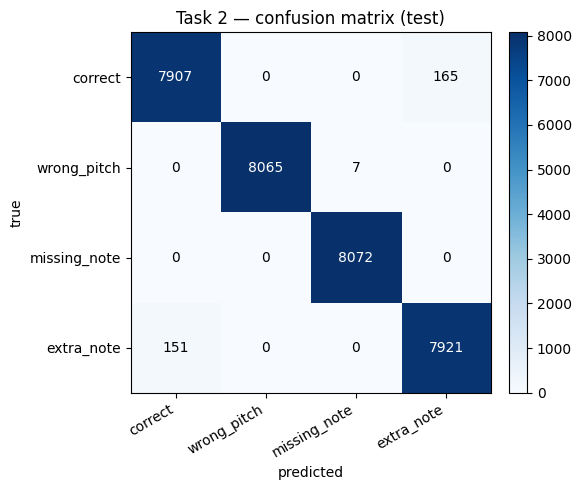

,precision,recall,f1,support
correct,0.981261,0.979559,0.980409,8072.0
wrong_pitch,1.000000,0.999133,0.999566,8072.0
missing_note,0.999134,1.000000,0.999567,8072.0
extra_note,0.979594,0.981293,0.980443,8072.0


In [14]:
confusion = np.asarray(test_metrics["confusion_matrix"])
fig, axis = plt.subplots(figsize=(6, 5))
image = axis.imshow(confusion, cmap="Blues")
axis.set_xticks(range(len(CLASS_NAMES)))
axis.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
axis.set_yticks(range(len(CLASS_NAMES)))
axis.set_yticklabels(CLASS_NAMES)
axis.set_xlabel("predicted")
axis.set_ylabel("true")
axis.set_title("Task 2 — confusion matrix (test)")
threshold = confusion.max() / 2.0 if confusion.max() else 0.0
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        axis.text(
            column, row, str(confusion[row, column]),
            ha="center", va="center",
            color="white" if confusion[row, column] > threshold else "black",
        )
fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "27_baseline_task2_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

per_class = test_metrics["per_class"]
class_table = pd.DataFrame(per_class).T
display(class_table)

## 9. Error analysis

In [15]:
analysis = test_meta.copy().reset_index(drop=True)
analysis["prediction"] = predictions
analysis["correct"] = (predictions == labels)
analysis["prob_true"] = probabilities[np.arange(len(labels)), labels]

rows = []
for soundfont, group in analysis.groupby("soundfont"):
    rows.append({
        "group": "soundfont",
        "value": soundfont,
        "n": len(group),
        "accuracy": float(group["correct"].mean()),
    })

wrong = analysis.loc[analysis["class_id"] == 1].copy()
wrong["abs_delta"] = wrong["pitch_delta"].abs()
wrong["delta_bin"] = pd.cut(
    wrong["abs_delta"],
    bins=[0, 1, 2, 3, 5, 12, np.inf],
    labels=["1", "2", "3", "4-5", "6-12", ">12"],
)
for bin_value, group in wrong.groupby("delta_bin", observed=True):
    rows.append({
        "group": "pitch_delta_bin",
        "value": str(bin_value),
        "n": len(group),
        "accuracy": float(group["correct"].mean()),
    })

for method, group in analysis.groupby("template_method"):
    rows.append({
        "group": "template_method",
        "value": str(method),
        "n": len(group),
        "accuracy": float(group["correct"].mean()),
    })

for fallback, group in analysis.groupby("fallback"):
    rows.append({
        "group": "fallback",
        "value": str(fallback),
        "n": len(group),
        "accuracy": float(group["correct"].mean()),
    })

analysis["duration_bin"] = pd.cut(
    analysis["duration_frames"],
    bins=[0, 4, 8, 16, 32, np.inf],
    labels=["1-4", "5-8", "9-16", "17-32", ">32"],
)
for bin_value, group in analysis.groupby("duration_bin", observed=True):
    rows.append({
        "group": "duration_bin",
        "value": str(bin_value),
        "n": len(group),
        "accuracy": float(group["correct"].mean()),
    })

error_analysis = pd.DataFrame(rows)
display(error_analysis)
error_analysis.to_csv(REPORTS_DIR / "baseline_task2_error_analysis.csv", index=False)

analysis[
    [
        "error_id", "notehead_id", "piece", "soundfont",
        "class_id", "class_name", "prediction", "prob_true", "correct",
    ]
].to_csv(REPORTS_DIR / "baseline_task2_test_predictions.csv", index=False)
print("Disimpan:", REPORTS_DIR / "baseline_task2_test_predictions.csv")

,group,value,n,accuracy
0,soundfont,ElectricPiano,8072,0.981417
1,soundfont,YamahaGrandPiano,8072,0.991452
2,soundfont,acoustic_piano_imis_1,8072,1.000000
3,soundfont,grand-piano-YDP-20160804,8072,0.987116
4,pitch_delta_bin,1,701,1.000000
5,pitch_delta_bin,2,659,1.000000
6,pitch_delta_bin,3,685,1.000000
7,pitch_delta_bin,4-5,1340,0.999254
8,pitch_delta_bin,6-12,4687,0.998720
9,template_method,bank,16140,0.990211


Disimpan: <project-root>\reports\baseline_task2_test_predictions.csv


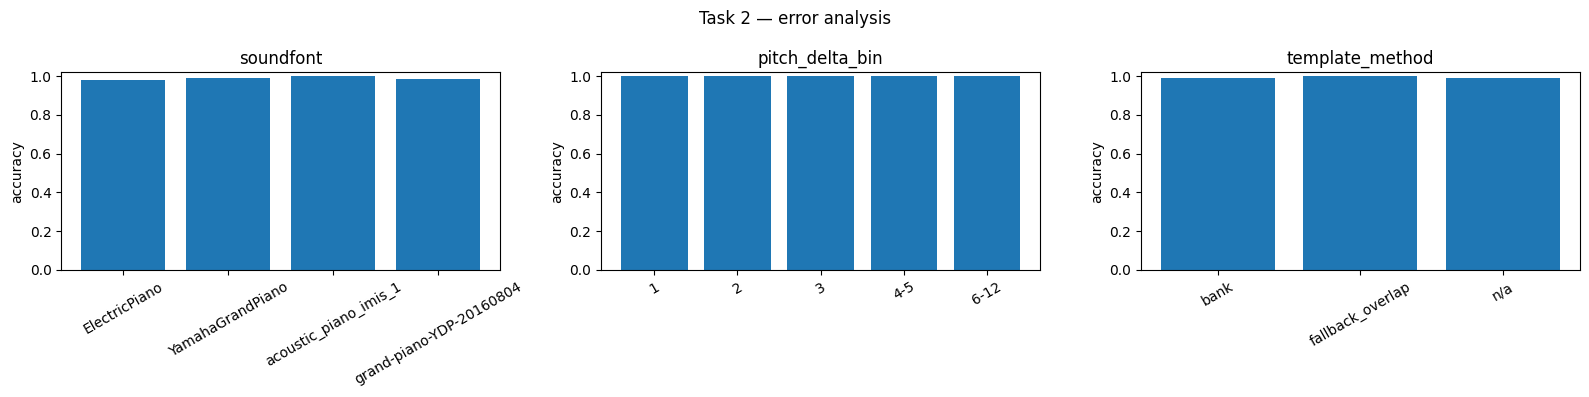

In [16]:
plot_groups = ["soundfont", "pitch_delta_bin", "template_method"]
fig, axes = plt.subplots(1, len(plot_groups), figsize=(16, 4))
for axis, group_name in zip(axes, plot_groups):
    subset = error_analysis.loc[error_analysis["group"] == group_name]
    if subset.empty:
        axis.set_visible(False)
        continue
    axis.bar(subset["value"], subset["accuracy"])
    axis.set_title(group_name)
    axis.set_ylim(0, 1.02)
    axis.set_ylabel("accuracy")
    axis.tick_params(axis="x", rotation=30)
fig.suptitle("Task 2 — error analysis")
fig.tight_layout()
fig.savefig(FIG_DIR / "28_baseline_task2_error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Simpan hasil

In [17]:
metrics_payload = {
    "paper": "Dorfer et al. (2018), TISMIR 1(1):22-33",
    "task": "Task 2 - performance error detection (adapted baseline)",
    "note": (
        "Task 2 is not a task in the original Dorfer paper. This is an adapted "
        "baseline: Task 1 encoders + fusion classifier. Score reference is the "
        "source notehead crop, not a full page/system."
    ),
    "config": CONFIG,
    "seed": SEED,
    "device": str(DEVICE),
    "checkpoint": str(CHECKPOINT_PATH),
    "task1_checkpoint": str(TASK1_CHECKPOINT),
    "best_checkpoint_epoch": checkpoint.get("epoch"),
    "best_val_metrics": checkpoint.get("val_metrics"),
    "test_metrics": test_metrics,
    "binary_correct_vs_error": binary,
    "error_type_3class": error_type_metrics,
    "history": history,
    "error_analysis": error_analysis.to_dict(orient="records"),
}
save_json(REPORTS_DIR / "baseline_task2_metrics.json", metrics_payload)
print("Disimpan:", REPORTS_DIR / "baseline_task2_metrics.json")

Disimpan: <project-root>\reports\baseline_task2_metrics.json


## 11. Catatan

Adapted baseline; error sintetis; test 3 piece; correct vs extra note paling sulit.